# 4x4 J1-J2 XXZ local quench: ⟨Sz⟩ on the quenched site

tVMC with a 1-site local rotation (`quench_dynamics/tvmc_quench_4x4/run_rot.py`) and
standard tVMC (`run_std.py`) against exact diagonalisation (`quench_dynamics/ed_dynamics_heisen.py`).
Run the three scripts first; this notebook only reads their outputs.

Colour rule for every figure: **blue = standard method (std)**, **red = local rotation (rot)**, black = exact reference.


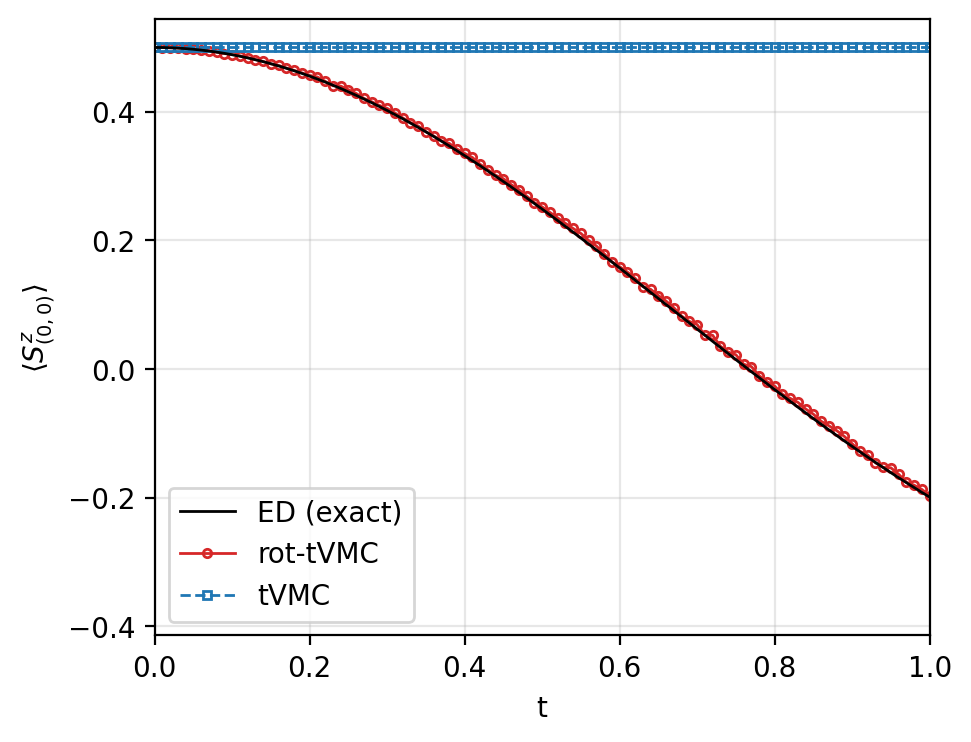

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")


QD = os.path.join(os.getcwd(), "quench_dynamics")
TAG = "4x4_pbc_j2_0.0_delta_0.0"
LY = 4
def site(x, y):
    return x * LY + y
EXCI_XY = (0, 0)
EXCI_POS = site(*EXCI_XY)
T_MAX = 2.0

ed = np.load(os.path.join(QD, "ed_reference", f"ed_dynamics_{TAG}.npz"))
rot = np.load(os.path.join(QD, "tvmc_quench_4x4", "results", f"history_rotsr_{TAG}.npz"))
std = np.load(os.path.join(QD, "tvmc_quench_4x4", "results", f"history_std_{TAG}.npz"))

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(ed["times"], ed["sz_all"][:, EXCI_POS], "k-", lw=1, label="ED (exact)", zorder=999)
ax.plot(rot["times"], rot["sz_all"][:, EXCI_POS], "-o", ms=3, lw=1, color="C3", label="rot-tVMC", markerfacecolor='none')
ax.plot(std["times"], std["sz_all"][:, EXCI_POS], "--s", ms=3, lw=1, color="C0", label="tVMC", markerfacecolor='none')
ax.set(xlim=(0, T_MAX), xlabel="t", ylabel=rf"$\langle S^z_{{{EXCI_XY}}} \rangle$")
ax.grid(alpha=0.3)
ax.legend()
ax.set_xlim(0,1)
plt.show()


## p-tVMC (projected tVMC)

Same quench with the product-expansion scheme of `quench_dynamics/ptvmc_quench_4x4/run_rot.py`
(fixed 2-site Hadamard rotation on the bond containing the quenched site) and `run_std.py`
(no rotation). Left: ⟨Sz⟩ on the quenched site against ED. Right: the inner infidelity
minimisation, one point per natural-gradient iteration (`n_iter` iterations per compression,
`stages` compressions per time step). Set `PTVMC_RUN_TAG` to the `run_tag` of `ptvmc_quench_4x4/config.toml`
(`""` for the shipped config, `"smoke_rw"` for the 20-step smoke test).

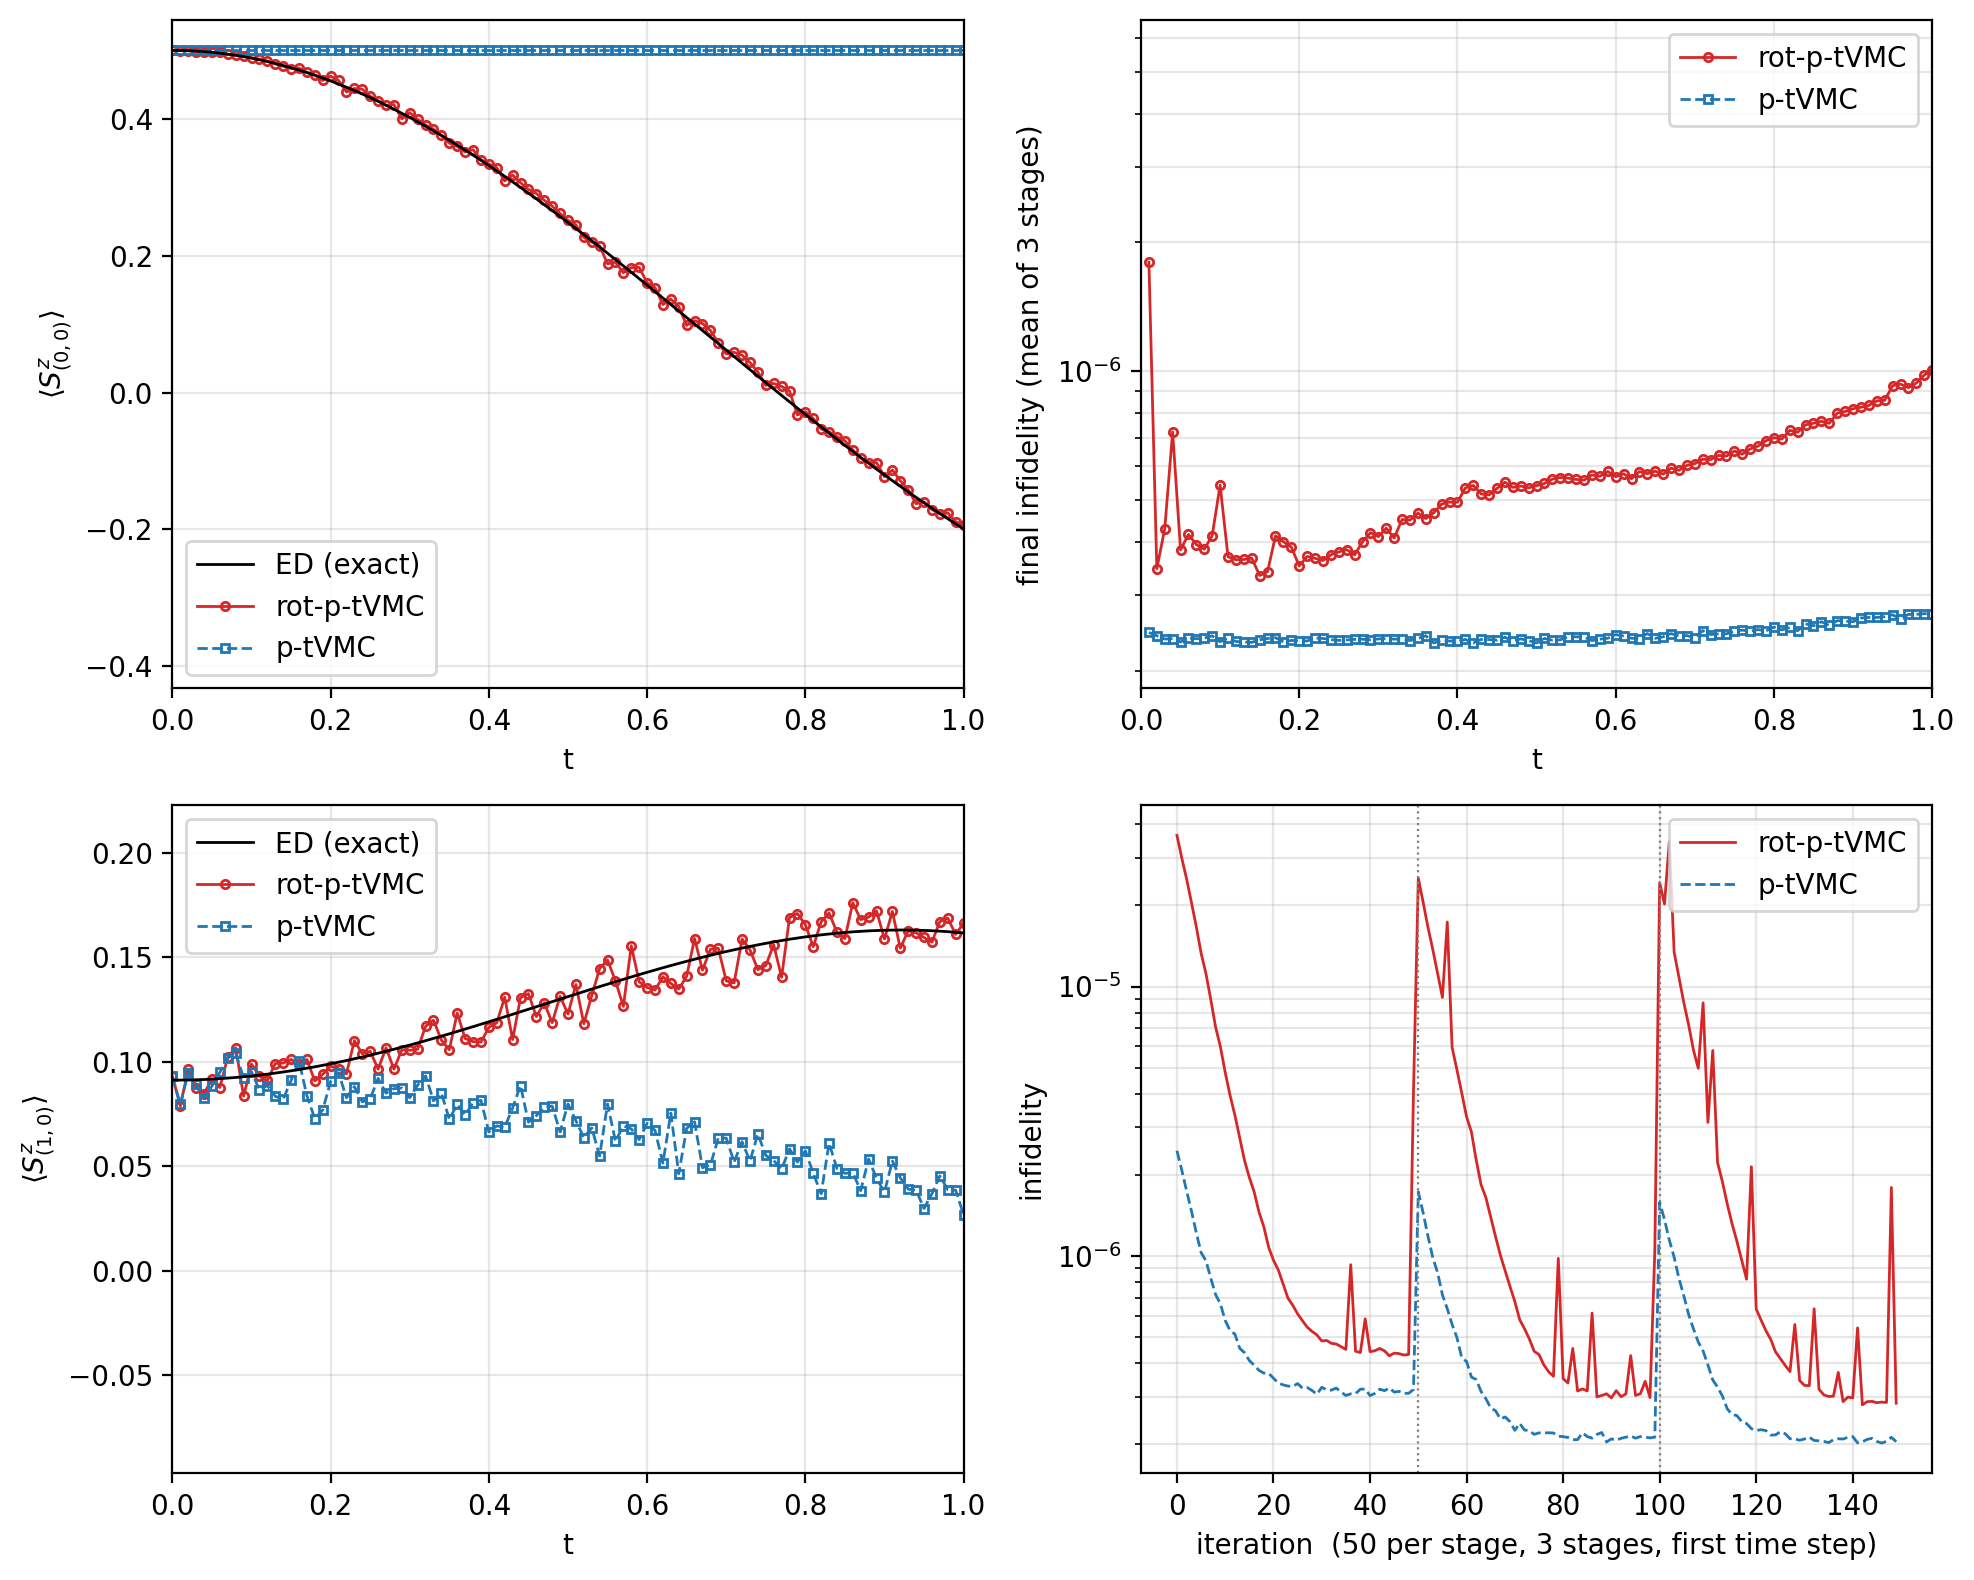

In [28]:
PTVMC_RUN_TAG = "regress"
_pt = TAG if not PTVMC_RUN_TAG else f"{TAG}_{PTVMC_RUN_TAG}"
PT = os.path.join(QD, "ptvmc_quench_4x4", "results")

prot = np.load(os.path.join(PT, f"history_rotsr_{_pt}.npz"))
pstd = np.load(os.path.join(PT, f"history_std_{_pt}.npz"))
irot = np.load(os.path.join(PT, f"infidelity_rot_{_pt}.npz"))
istd = np.load(os.path.join(PT, f"infidelity_std_{_pt}.npz"))
n_iter, stages = int(irot["n_iter"]), int(irot["stages"])
per_dt = n_iter * stages


def final_infidelity(d):
    """Mean over the `stages` compressions of the last-iteration infidelity, per time step."""
    inf = d["infidelity"][: len(d["infidelity"]) // per_dt * per_dt].reshape(-1, stages, n_iter)
    return inf[:, :, -1].mean(axis=1)


fig, ((ax, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 8))

for axi, (x, y) in ((ax, EXCI_XY), (ax3, (1, 0))):
    i = site(x, y)
    axi.plot(ed["times"], ed["sz_all"][:, i], "k-", lw=1, label="ED (exact)", zorder=999)
    axi.plot(prot["times"], prot["sz_all"][:, i], "-o", ms=3, lw=1, color="C3", label="rot-p-tVMC", markerfacecolor='none')
    axi.plot(pstd["times"], pstd["sz_all"][:, i], "--s", ms=3, lw=1, color="C0", label="p-tVMC", markerfacecolor='none')
    axi.set(xlim=(0, T_MAX), xlabel="t", ylabel=rf"$\langle S^z_{{({x},{y})}} \rangle$")
    axi.grid(alpha=0.3)
    axi.legend()
    axi.set_xlim(0,1)

f_rot, f_std = final_infidelity(irot), final_infidelity(istd)
ax2.semilogy(prot["times"][1:len(f_rot) + 1], f_rot, "-o", ms=3, lw=1, color="C3", label="rot-p-tVMC", markerfacecolor='none')
ax2.semilogy(pstd["times"][1:len(f_std) + 1], f_std, "--s", ms=3, lw=1, color="C0", label="p-tVMC", markerfacecolor='none')
ax2.set(xlabel="t", ylabel=f"final infidelity (mean of {stages} stages)")
ax2.grid(alpha=0.3, which="both")
ax2.legend()
ax2.set_xlim(0,1)

ax4.semilogy(np.arange(per_dt), irot["infidelity"][:per_dt], "-", lw=1, color="C3", label="rot-p-tVMC")
ax4.semilogy(np.arange(per_dt), istd["infidelity"][:per_dt], "--", lw=1, color="C0", label="p-tVMC")
for k in range(1, stages):
    ax4.axvline(k * n_iter, color="gray", lw=0.8, ls=":")
ax4.set(xlabel=f"iteration  ({n_iter} per stage, {stages} stages, first time step)", ylabel="infidelity")
ax4.grid(alpha=0.3, which="both")
ax4.legend()

plt.tight_layout()
plt.show()


## Parity mixing (8-site TFIM chain)

Support-mismatch benchmark of arXiv:2603.18148 (blurred sampling), Fig. 5(a): the equal-weight
even-Z-parity state $|\psi_{\rm even}\rangle$ evolved with $H = J\sum Z_iZ_j + h\sum X_i$ ($J=h=1$).
$P_Z=\langle\prod_i Z_i\rangle$ from `parity_mixing/run_rot.py` (1-site Hadamard rotation) and
`run_std.py` (plain tVMC) against ED (`parity_mixing/ed_dynamics_tfim.py`); cached RK45, one point
per accepted step. The plain sampler sees no odd-parity configuration and $P_Z$ lags behind.


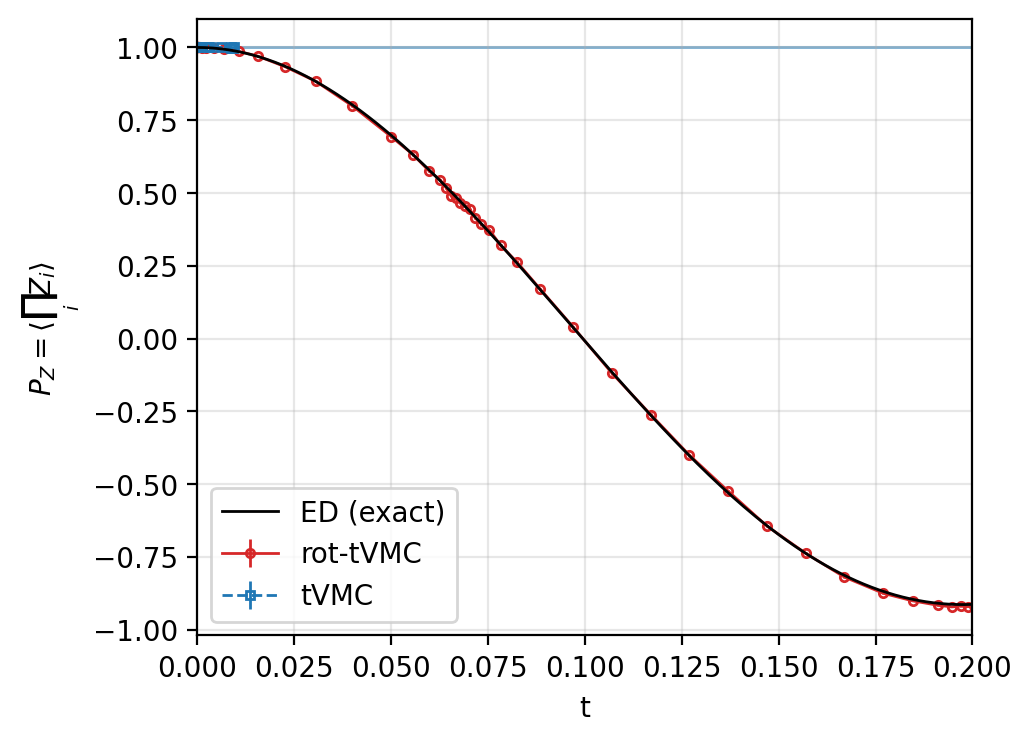

In [29]:
PM = os.path.join(os.getcwd(), "parity_mixing")
PM_TAG = "tfim_8x1_pbc_J1.0_h1.0_alpha4_proj2_pd0.001"
PM_T_MAX = 0.2
PM_T_STD = 0.01

ped = np.load(os.path.join(PM, "ed_reference", f"ed_dynamics_{PM_TAG}.npz"))
prot_pm = np.load(os.path.join(PM, "results", f"history_rot_{PM_TAG}.npz"))
pstd_pm = np.load(os.path.join(PM, "results", f"history_std_{PM_TAG}.npz"))
m_std = pstd_pm["times"] <= PM_T_STD

fig, ax = plt.subplots(figsize=(5, 4))
ax.axhline(1.0, color="C0", lw=1, alpha=0.6, zorder=0)
ax.plot(ped["times"], ped["parity"], "k-", lw=1, label="ED (exact)", zorder=999)
ax.errorbar(prot_pm["times"], prot_pm["parity"], yerr=prot_pm["parity_err"], fmt="-o", ms=3, lw=1, color="C3", label="rot-tVMC", markerfacecolor='none')
ax.errorbar(pstd_pm["times"][m_std], pstd_pm["parity"][m_std], yerr=pstd_pm["parity_err"][m_std], fmt="--s", ms=3, lw=1, color="C0", label="tVMC", markerfacecolor='none')
ax.set(xlim=(0, PM_T_MAX), xlabel="t", ylabel=r"$P_Z = \langle \prod_i Z_i \rangle$")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.show()


## Ground state (4x4 J1-J2 Heisenberg, lookup ansatz)

Energy per SR sweep of the exact lookup-table ansatz on the 4x4 PBC $J_1$-$J_2$ Heisenberg model
($J_2 = 0.5$): standard NetKet VMC-SR (`gs_optimization/run_std.py`) and rot-SR started from the
std checkpoint of sweep `GS_INIT_SWEEP` (`run_rot.py`, one random Sz-conserving bond rotation per
sweep, cycling through all NN + NNN bonds), against ED (`gs_optimization/ed_ground_state.py`).
Right: relative error $(E - E_{\rm ED})/|E_{\rm ED}|$ with a 100-sweep running mean.


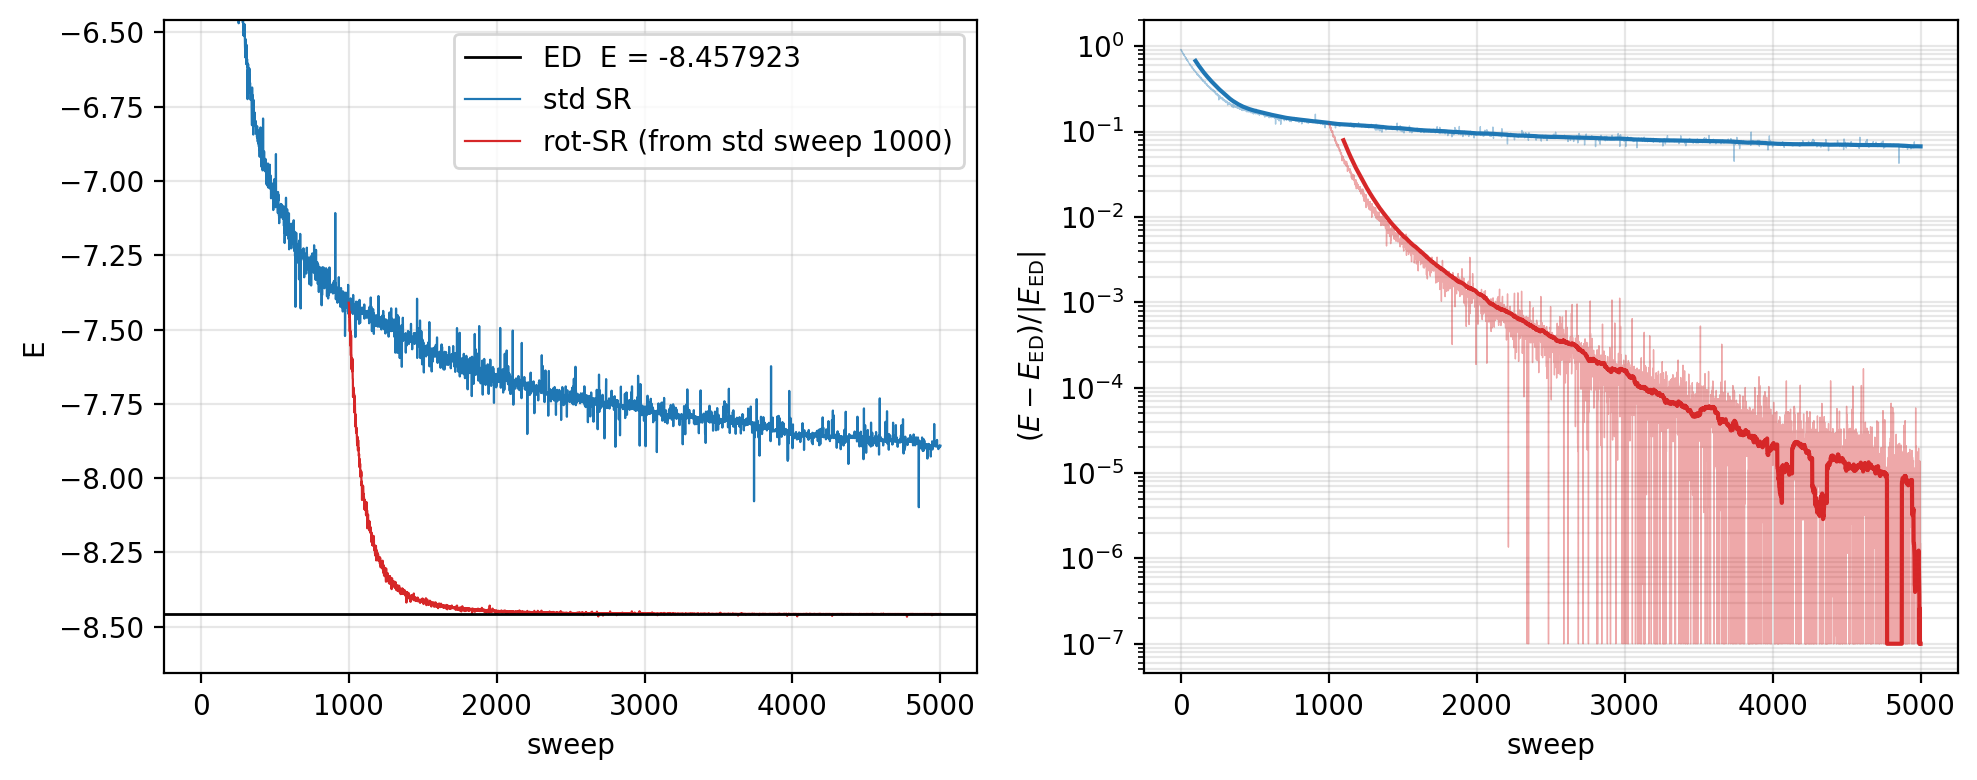

In [30]:
GS = os.path.join(os.getcwd(), "gs_optimization")
GS_TAG = "heis_4x4_pbc_j1_1.0_j2_0.5"
GS_J2 = 0.5
GS_SMOOTH = 100

e_ed = float(np.min(np.load(os.path.join(GS, "ed_reference", f"ed_gs_j2_{GS_J2}.npz"))["eigvals"]))
gstd = np.load(os.path.join(GS, "results", f"history_std_{GS_TAG}.npz"))
grot = np.load(os.path.join(GS, "results", f"history_rot_{GS_TAG}.npz"))
GS_INIT_SWEEP = int(grot["init_sweep"])

fig, (ax, axr) = plt.subplots(1, 2, figsize=(10, 4))
ax.axhline(e_ed, color="k", lw=1, label=f"ED  E = {e_ed:.6f}", zorder=999)
ax.plot(gstd["sweeps"], gstd["energies"], "-", lw=0.8, color="C0", label="std SR")
ax.plot(grot["sweeps"], grot["energies"], "-", lw=0.8, color="C3", label=f"rot-SR (from std sweep {GS_INIT_SWEEP})")
ax.set(xlabel="sweep", ylabel="E", ylim=(e_ed - 0.2, e_ed + 2.0))
ax.grid(alpha=0.3)
ax.legend(loc="upper right")

for h, color in ((gstd, "C0"), (grot, "C3")):
    rel = (h["energies"] - e_ed) / abs(e_ed)
    axr.semilogy(h["sweeps"], np.maximum(rel, 1e-7), lw=0.5, color=color, alpha=0.4)
    if len(rel) > GS_SMOOTH:
        sm = np.convolve(rel, np.ones(GS_SMOOTH) / GS_SMOOTH, mode="valid")
        axr.semilogy(h["sweeps"][GS_SMOOTH - 1:], np.maximum(sm, 1e-7), lw=1.5, color=color)
axr.set(xlabel="sweep", ylabel=r"$(E - E_{\rm ED}) / |E_{\rm ED}|$")
axr.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()
